**Exploratory Data Analysis**

In [580]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [581]:
df=pd.read_csv('/content/archive (1).zip')

In [582]:
df.shape

(891, 12)

In [583]:
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [584]:
df.columns.values


array(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype=object)

In [585]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [586]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [587]:
df.drop(columns='Cabin',inplace=True)

In [588]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [589]:
from sklearn.impute import SimpleImputer
imp=SimpleImputer(strategy='mean')
val=imp.fit_transform(df[['Age']])
df.drop(columns='Age')
df['Age']=val
frequent_val=df['Embarked'].mode()
df['Embarked'] = df['Embarked'].fillna(frequent_val[0])

In [590]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


out of 891 62% people died


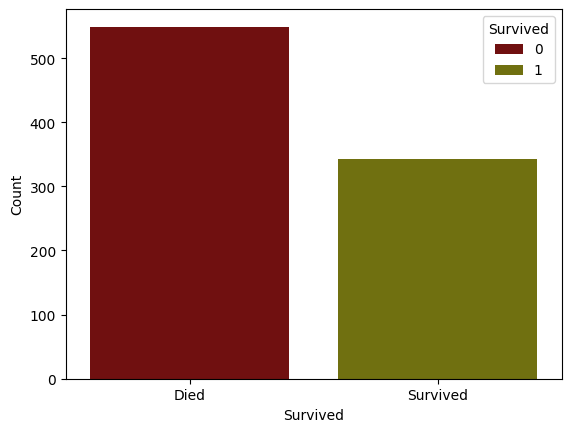

In [591]:
#univariate Analysis
sns.countplot(x=df['Survived'],data=df,hue='Survived',palette=['maroon','olive'])
plt.xticks(ticks=[0,1],labels=['Died','Survived'])
plt.xlabel('Survived')
plt.ylabel('Count')
death_percent=round((df['Survived'].value_counts()[0]/df['Survived'].count())*100)
print('out of 891 {}% people died'.format(death_percent))

Pclass
3    55.106622
1    24.242424
2    20.650954
Name: count, dtype: float64


<Axes: xlabel='Pclass', ylabel='count'>

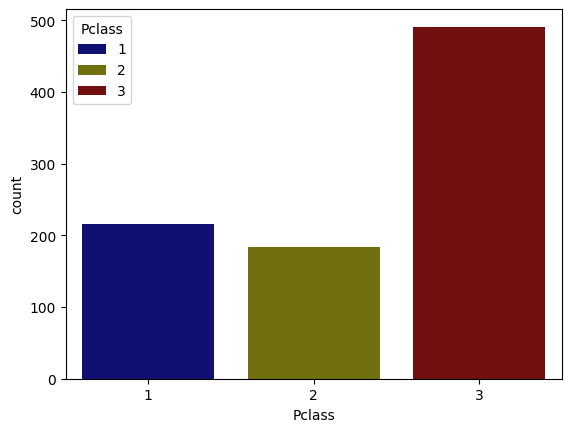

In [592]:
from matplotlib._api import suppress_matplotlib_deprecation_warning
print((df['Pclass'].value_counts()/891)*100)
sns.countplot(x=df['Pclass'],data=df,hue='Pclass',palette=['navy','olive','maroon'])

Sex
male      64.758698
female    35.241302
Name: count, dtype: float64


<Axes: xlabel='Sex', ylabel='count'>

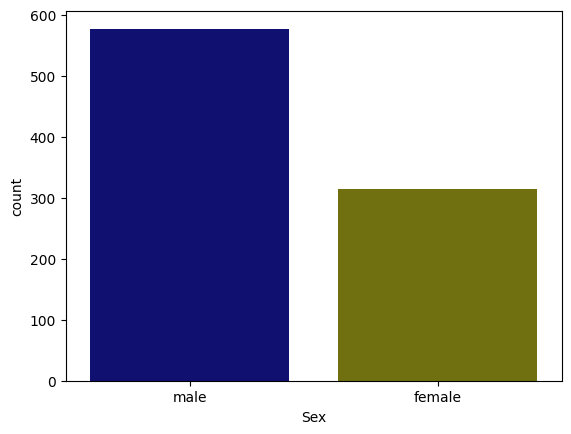

In [593]:
print((df['Sex'].value_counts()/891)*100)
sns.countplot(x=df['Sex'],data=df,hue='Sex',palette=['navy','olive'])

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


<Axes: xlabel='Embarked', ylabel='count'>

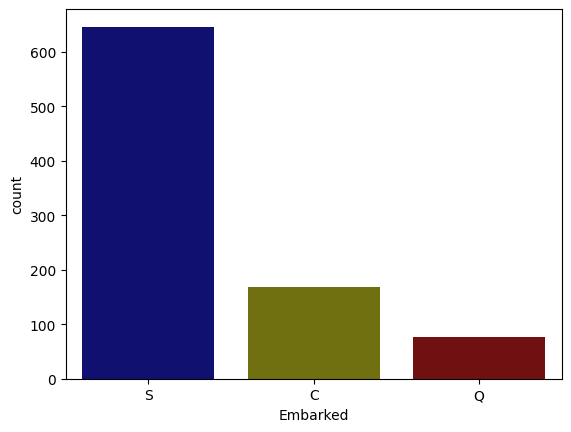

In [594]:
print(df['Embarked'].value_counts())
sns.countplot(x=df['Embarked'],data=df,hue='Embarked',palette=['navy','olive','maroon'])

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64


<Axes: xlabel='SibSp', ylabel='count'>

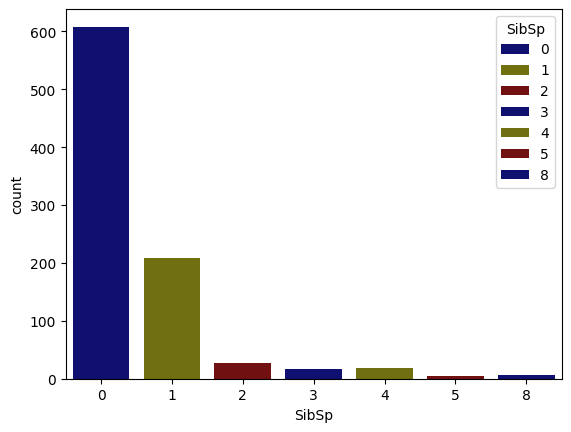

In [595]:
print(df['SibSp'].value_counts())
sns.countplot(x=df['SibSp'],data=df,hue='SibSp',palette=['navy','olive','maroon','navy','olive','maroon','navy'])

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


<Axes: xlabel='Parch', ylabel='count'>

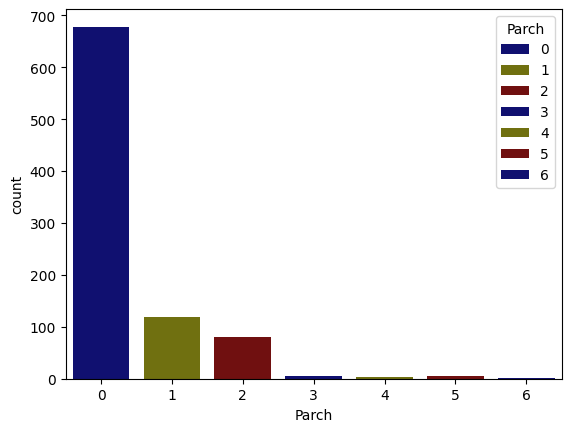

In [596]:
print(df['Parch'].value_counts())
sns.countplot(x=df['Parch'],data=df,hue='Parch',palette=['navy','olive','maroon','navy','olive','maroon','navy'])

0.4344880940129925
0.9662793026645233


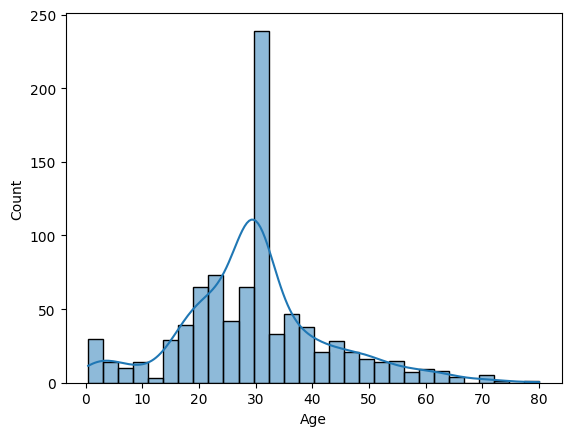

In [597]:
sns.histplot(x=df['Age'],data=df,kde=True)  #conclusion mostly normal
print(df['Age'].skew())
print(df['Age'].kurt())

<Axes: xlabel='Age'>

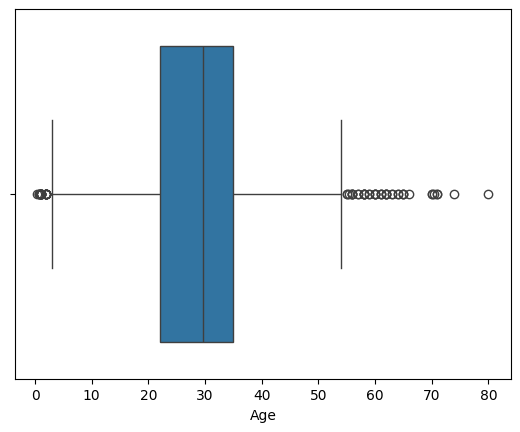

In [598]:
sns.boxplot(x=df['Age'])

4.787316519674893
33.39814088089868


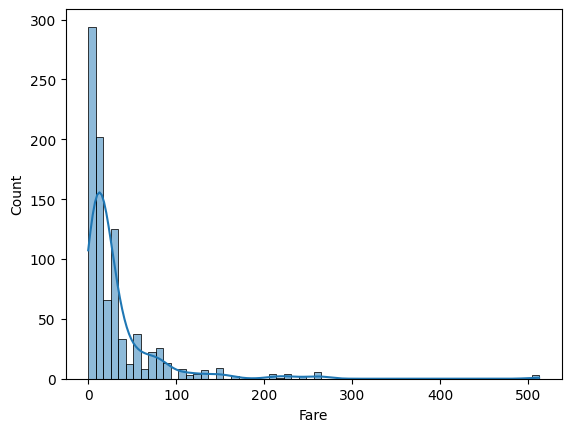

In [599]:
sns.histplot(x=df['Fare'],data=df,kde=True)
print(df['Fare'].skew())
print(df['Fare'].kurt())


<Axes: xlabel='Fare'>

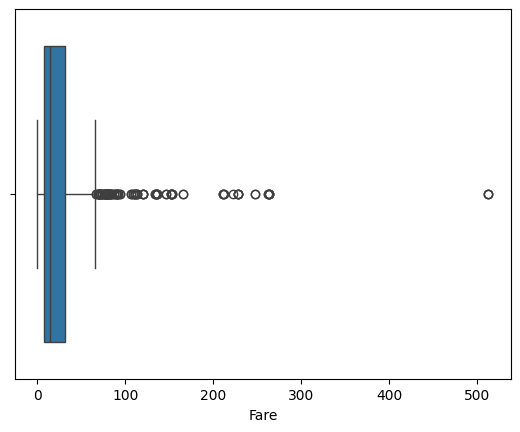

In [600]:
sns.boxplot(x=df['Fare'])

In [601]:
df[(df['Fare']>200)&(df['Fare']<300)].shape[0]


17

In [602]:
df[df['Fare']>300].shape[0]  #conclusion skewed data

3

**MULTIVARIATE ANALYSIS**

<Axes: xlabel='Survived', ylabel='count'>

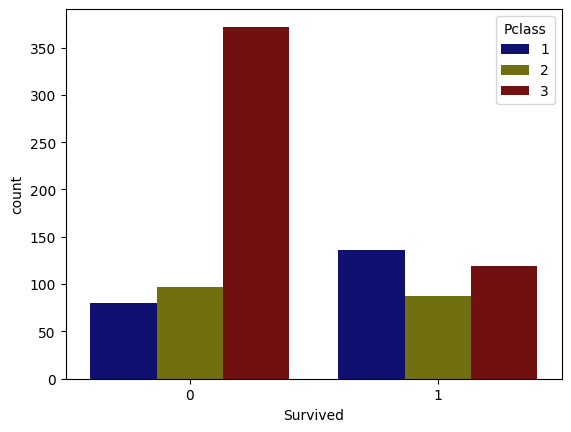

In [603]:
sns.countplot(x=df['Survived'],data=df,hue='Pclass',palette=['navy','olive','maroon'])

In [604]:
pd.crosstab(df['Pclass'],df['Survived']).apply(lambda r:round((r/r.sum())*100,1),axis=1)

Survived,0,1
Pclass,,
1,37.0,63.0
2,52.7,47.3
3,75.8,24.2


Survived,0,1
Sex,,
female,25.8,74.2
male,81.1,18.9


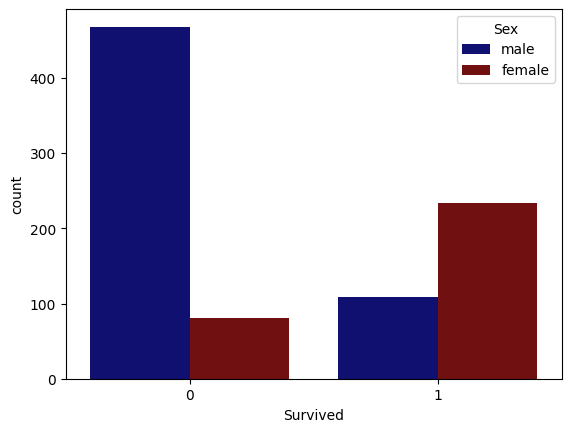

In [605]:
sns.countplot(x=df['Survived'],data=df,hue='Sex',palette=['navy','maroon'])
pd.crosstab(df['Sex'],df['Survived']).apply(lambda r:round((r/r.sum())*100,1),axis=1)

Survived,0,1
Embarked,,
C,44.6,55.4
Q,61.0,39.0
S,66.1,33.9


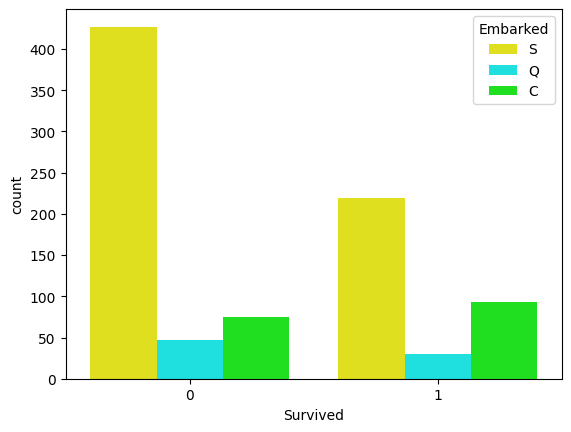

In [606]:
sns.countplot(x=df['Survived'],data=df,hue='Embarked',palette=['yellow','cyan','lime'])
pd.crosstab(df['Embarked'],df['Survived']).apply(lambda r:round((r/r.sum())*100,1),axis=1)

<Axes: xlabel='Age', ylabel='Count'>

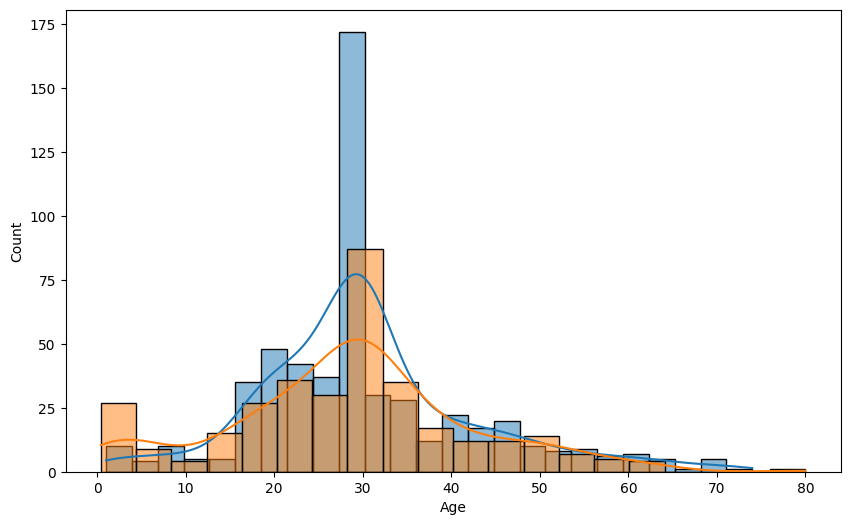

In [607]:
plt.figure(figsize=(10,6))
sns.histplot(df[df['Survived']==0]['Age'],kde=True)
sns.histplot(df[df['Survived']==1]['Age'],kde=True)

<Axes: xlabel='Fare', ylabel='Count'>

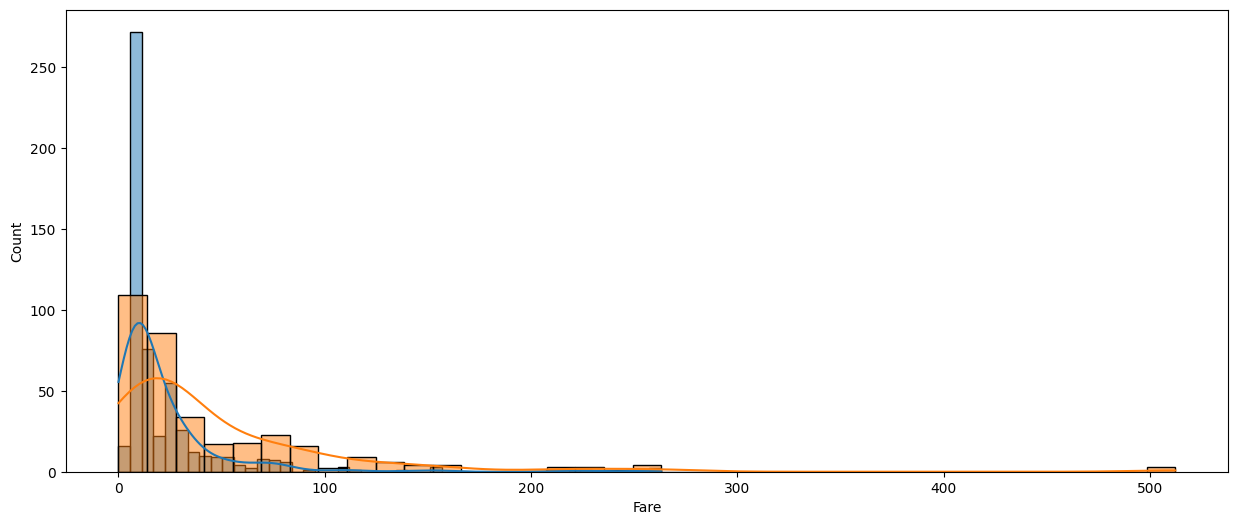

In [608]:
plt.figure(figsize=(15,6))
sns.histplot(df[df['Survived']==0]['Fare'],kde=True)
sns.histplot(df[df['Survived']==1]['Fare'],kde=True)

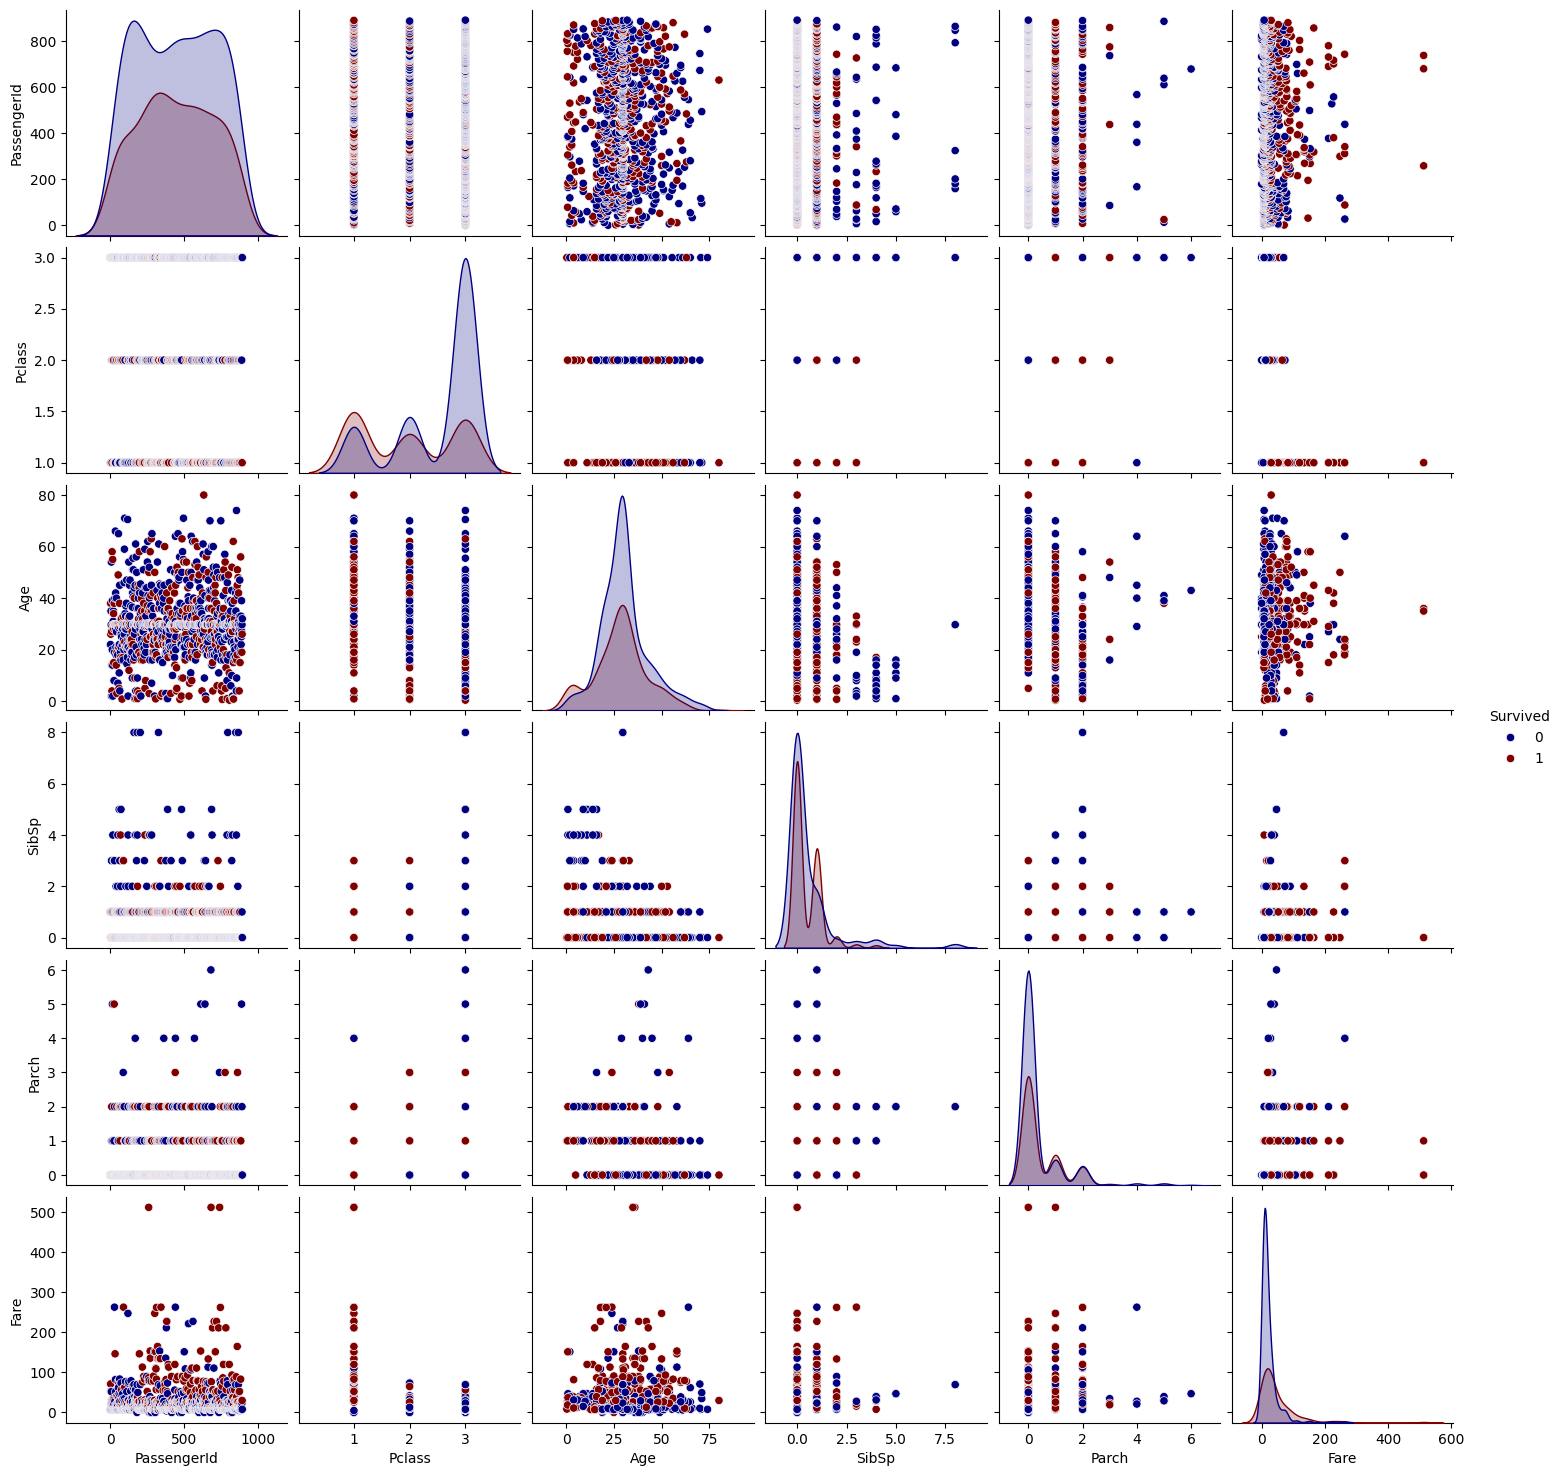

In [609]:

sns.pairplot(df,hue='Survived',palette=['navy','maroon'])

In [611]:
df['Family_size']=df['Parch']+df['SibSp'] #high relation


In [612]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Family_size
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


In [613]:
def family_type(number):
  if number==0:
    return "Alone"
  elif number>0 and number<=4:
    return "Medium"
  else:
    return "Large"

In [614]:
df['Family_type']=df['Family_size'].apply(family_type)

In [615]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Family_size,Family_type
614,615,0,3,"Brocklebank, Mr. William Alfred",male,35.000000,0,0,364512,8.0500,S,0,Alone
859,860,0,3,"Razi, Mr. Raihed",male,29.699118,0,0,2629,7.2292,C,0,Alone
123,124,1,2,"Webber, Miss. Susan",female,32.500000,0,0,27267,13.0000,S,0,Alone
765,766,1,1,"Hogeboom, Mrs. John C (Anna Andrews)",female,51.000000,1,0,13502,77.9583,S,1,Medium
131,132,0,3,"Coelho, Mr. Domingos Fernandeo",male,20.000000,0,0,SOTON/O.Q. 3101307,7.0500,S,0,Alone


In [616]:
df=df.drop(columns=['SibSp','Parch','Family_size'])

Survived,0,1
Family_type,,
Alone,69.6,30.4
Large,85.1,14.9
Medium,44.0,56.0


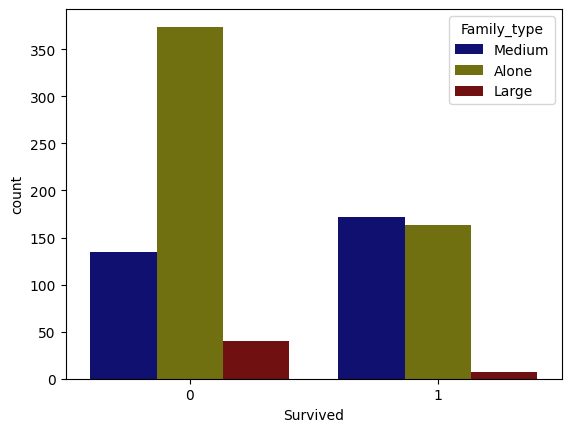

In [617]:
sns.countplot(x=df['Survived'],data=df,hue='Family_type',palette=['navy','olive','maroon'])
pd.crosstab(df['Family_type'],df['Survived']).apply(lambda r:round((r/r.sum())*100,1),axis=1)

In [618]:
df=df[df['Age']<(df['Age'].mean()+3*df['Age'].std())]
df.shape

(884, 10)

<Axes: xlabel='Fare', ylabel='Count'>

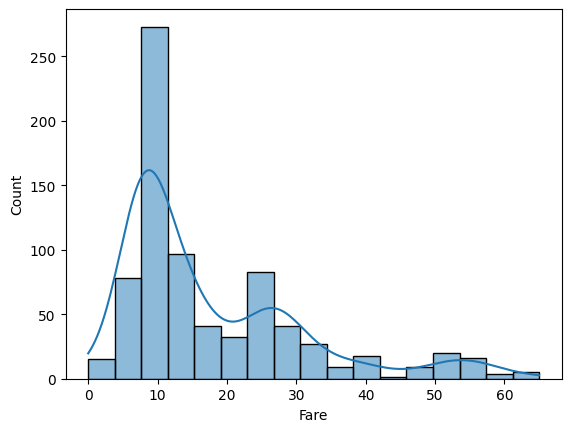

In [619]:
q1=df['Fare'].quantile(0.25)
q3=df['Fare'].quantile(0.75)
iqr=q3-q1
upper_bound=q3+1.5*iqr
lower_bound=q1-1.5*iqr
df=df[(df['Fare']>lower_bound)&(df['Fare']<=upper_bound)]
sns.histplot(x=df['Fare'],kde=True)


In [620]:
df=pd.get_dummies(data=df,columns=['Pclass','Sex','Embarked','Family_type'],drop_first=True)

<Axes: >

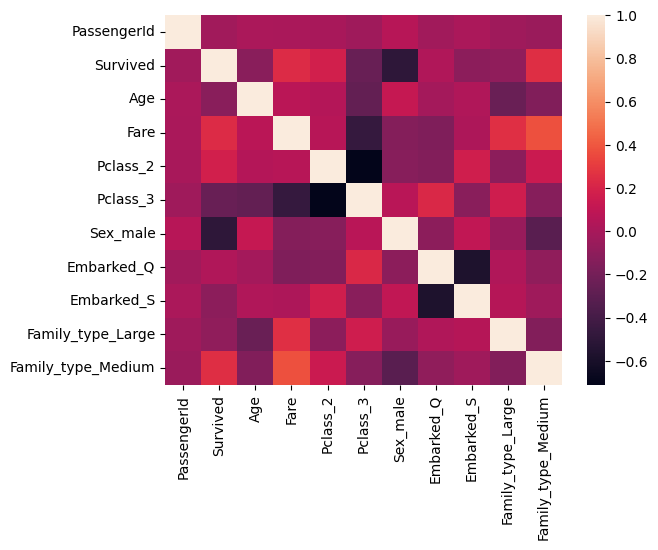

In [621]:
sns.heatmap(df.corr(numeric_only=True))